In [1]:
import os
import warnings
import folium
import rasterio
import shapely
import cmocean
import math

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import nivapy3 as nivapy
import matplotlib.pyplot as plt
import numpy as np

from matplotlib.backends.backend_pdf import PdfPages
from geopandas import GeoSeries
from shapely.geometry import Polygon

plt.style.use("ggplot")
warnings.simplefilter("ignore")

In [2]:
eng = nivapy.da.connect_postgis()

Connection successful.


# Read in delineated catchments and outlet points

In [3]:
# Directory to read raw shapefile from and to write processed shp to
cur_dir = r"/home/jovyan/shared/common/norsink/spatial/monitored_chem_catchments"
dem_res = 20  # m

# Monitoring points

# Over this number of samples, the site is classified as high priority (e.g. for manual checking)
n_samps_priority = 9

# Delineated catchments
cat_gdf = gpd.read_file(os.path.join(cur_dir, "shp", f"raw_catchments_vm-quant_{dem_res}-dem.shp"))

rename_cols_dict = {
    'WaterLocat': 'site_code',
    'WaterLoc_1': 'site_id',
    'n_years_wi': 'n_years',
    'av_samplin': 'av_freq'
}

cat_gdf = cat_gdf.rename(columns=rename_cols_dict)

pts_gdf = gpd.GeoDataFrame(
    cat_gdf.copy(),
    geometry=gpd.points_from_xy(cat_gdf["lon"], cat_gdf["lat"]),
    crs="EPSG:4326"
)
pts_gdf = pts_gdf.to_crs(cat_gdf.crs)

# Priority points and associated catchments
priority_pts_gdf = pts_gdf.loc[pts_gdf['n_samples'] > n_samps_priority].copy()
priority_cats_gdf = cat_gdf.loc[cat_gdf['n_samples'] > n_samps_priority].copy()
print("Number of 'priority' sites:", len(priority_pts_gdf))

cat_gdf.head()

Number of 'priority' sites: 2880


,site_code,lon,lat,site_id,Name,start_year,end_year,n_years,n_samples,av_freq,area_km2,samples_pe,geometry
0,001-119928,11.653745,59.476520,119928,Oppstrøms Bommen RA,2011,2025,14.0,14,1.00,1008.505005,0.013882,"POLYGON ((306680 6664180, 306760 6664180, 3067..."
1,001-119929,11.654461,59.472300,119929,Nedstrøms Bommen RA,2011,2025,14.0,14,1.00,1009.065359,0.013874,"POLYGON ((306680 6664180, 306760 6664180, 3067..."
2,001-30653,11.437438,59.070299,30653,YSTE YSTEHEDEBEKKEN,1987,1987,1.0,4,4.00,6.702626,0.596781,"POLYGON ((298520 6555300, 298640 6555300, 2986..."
3,001-30683,11.295421,59.121185,30683,"Unnebergbekken, UNNE",1987,2016,29.1,5,0.17,15.372746,0.325251,"POLYGON ((290660 6567260, 290680 6567260, 2906..."
4,001-30687,11.528412,58.987892,30687,ØRB2 ØRBEKKEN,1991,1991,1.0,4,4.00,42.291160,0.094582,"POLYGON ((305560 6548480, 305560 6548500, 3055..."


In [25]:
cat_gdf.describe()

,lon,lat,site_id,start_year,end_year,n_years,n_samples,av_freq,area_km2
count,10857.000000,10857.000000,10857.000000,10857.000000,10857.000000,10857.000000,10857.000000,10857.000000,10857.000000
mean,9.904482,61.048435,76946.894538,2014.665193,2019.189555,5.017583,16.674035,3.358669,286.328611
std,3.479283,2.631746,29682.896958,8.595362,6.870217,6.624304,72.678605,6.669413,1846.229166
min,4.693305,58.015685,-11.000000,1980.000000,1983.000000,1.000000,1.000000,0.060000,0.198919
25%,7.972197,59.491976,50840.000000,2011.000000,2017.000000,1.000000,2.000000,1.000000,1.051199
50%,9.906098,60.165520,83016.000000,2017.000000,2021.000000,1.000000,4.000000,2.000000,4.513914
75%,10.983130,61.527778,102585.000000,2021.000000,2024.000000,7.000000,10.000000,4.000000,28.474989
max,30.952229,70.962425,127364.000000,2025.000000,2026.000000,44.900000,2020.000000,246.040000,41698.296544


In [26]:
# x = 'n_samples'
# y = 'area_km2'
# plt.scatter(cat_gdf['n_samples'], cat_gdf['area_km2'], marker='o')
# plt.yscale('log')
# plt.xscale('log')
# plt.xlabel(x)
# plt.ylabel(y)
# plt.show()

**Comments:**
- 75% of sites are south of 61.5 degrees, i.e. southern bias
- 75% of sites only have data after 2017, i.e. late bias
- Most sites don't have much data: 75% have <= 10 data points gathered over a period of <= 7 years
- Catchment size:
  - Typically small, with 75% having an area < ~30 km2
  - Median area is 4.5 km2
  - 25% of sites have an area of ~1km2. So if we drop small catchments using a threshold of around 1 km2, we will loose about a quarter of the sites.

Classify sites as "priority" for manual checking if they have >= 10 data points (i.e. 25% of sites, before filtering of e.g. lake or too-small catchs).

In [27]:
# # Interactive map of outlets
# pts_gdf = pts_gdf.rename({'lon': 'longitude', 'lat': 'latitude'}, axis=1).reset_index()
# nivapy.spatial.quickmap(
#     pts_gdf, kartverket=True, popup='site_code', aerial_imagery=False
# )

# Interactive html map

In [28]:
# m = folium.Map(location=[69.83, 22.05], zoom_start=8)

# # Add catchment polygons
# for _, r in cat_gdf.to_crs(epsg=4326).iterrows():
#     # assuming each polygon is a shapely.geometry.Polygon
#     sim_geo = gpd.GeoSeries(r["geometry"])
#     geo_j = sim_geo.to_json()
#     geo_j = folium.GeoJson(
#         data=geo_j,
#         style_function=lambda x: {"fillColor": "orange", "fillOpacity": 0.05},
#         tooltip=str(r["site_code"]),
#     )
#     folium.Popup(r["site_code"]).add_to(geo_j)
#     geo_j.add_to(m)

# # Add points
# for _, r in pts_gdf.to_crs(epsg=4326).iterrows():
#     folium.CircleMarker(
#         location=[r["geometry"].y, r["geometry"].x],
#         popup=str(r["site_code"]),
#         color="red",
#         fill=True,
#         fill_color="red",
#         radius=5,
#         icon=folium.Icon(color="red"),
#     ).add_to(m)

# fpath = os.path.join(cur_dir, 'interactive_map.html')
# m.save(fpath)

# Make pdf thumbnail maps per catchment

In [29]:
def create_thumbnail_maps(
    cat_gdf,
    stn_gdf,
    pdf_path,
    nrows,
    ncols,
    site_id_col=None,
    site_name_col=None,
    area_col=None,
    n_samples_col=None,
    add_rivs=False,
    lake_gdf=None,
    dem=None,
    area_threshold=5,      # km². For catchs bigger than this, zoom in
    target_area_km2=2  #km2, to zoom to for larger catches
):
    """Multi-page thumbnail maps with optional DEM + river background"""

    n_plots = nrows * ncols
    n_pages = len(cat_gdf) // n_plots + (len(cat_gdf) % n_plots > 0)

    # DEM colormap
    dem_cmap = cmocean.tools.crop_by_percent(
        cmocean.cm.topo, 50, which='min'
    )

    # Optional station lookup
    stn_lookup = None
    if stn_gdf is not None and site_id_col is not None:
        stn_lookup = {
            row[site_id_col]: row
            for _, row in stn_gdf.iterrows()
        }

    with PdfPages(pdf_path) as pdf_pages:
        for page in range(n_pages):

            fig, axes = plt.subplots(
                nrows=nrows,
                ncols=ncols,
                figsize=(7.5, 10)
            )
            axes = axes.flatten()

            subset = cat_gdf.iloc[
                page * n_plots : (page + 1) * n_plots
            ]

            for i in range(len(subset)):
                ax = axes[i]

                row = subset.iloc[i]
                geom = row.geometry

                if geom is None:
                    continue

                # --- Base geometry bounds ---
                # minx, miny, maxx, maxy = geom.bounds

                # # Optional station
                # stn_row = None
                # if stn_lookup is not None and site_id_col is not None:
                #     stn_id = row[site_id_col]
                #     stn_row = stn_lookup.get(stn_id)

                #     if stn_row is not None:
                #         pt = stn_row.geometry
                #         minx = min(minx, pt.x)
                #         maxx = max(maxx, pt.x)
                #         miny = min(miny, pt.y)
                #         maxy = max(maxy, pt.y)

                # # Padding
                # pad_x = (maxx - minx) * 0.1 or 1
                # pad_y = (maxy - miny) * 0.1 or 1

                # minx -= pad_x
                # maxx += pad_x
                # miny -= pad_y
                # maxy += pad_y
                
                # --- Base geometry bounds ---
                minx, miny, maxx, maxy = geom.bounds
                
                # Station (guaranteed present)
                stn_id = row[site_id_col]
                stn_row = stn_lookup[stn_id]
                pt = stn_row.geometry
                
                # --- Smart zoom ---
                area_val = row[area_col]
                
                if area_val > area_threshold:
                    # center on station
                    cx, cy = pt.x, pt.y
                
                    # square window size (meters)
                    half_size = (target_area_km2 ** 0.5 * 1000) / 2

                    minx = cx - half_size
                    maxx = cx + half_size
                    miny = cy - half_size
                    maxy = cy + half_size

                else:
                    # expand bounds to include station
                    minx = min(minx, pt.x)
                    maxx = max(maxx, pt.x)
                    miny = min(miny, pt.y)
                    maxy = max(maxy, pt.y)

                    # padding
                    # pad_x = (maxx - minx) * 0.1 or 1
                    # pad_y = (maxy - miny) * 0.1 or 1

                    # to avoid weird verye narrow bounding boxes influencing padding
                    pad_x = max((maxx - minx) * 0.1, 50)
                    pad_y = max((maxy - miny) * 0.1, 50)

                    minx -= pad_x
                    maxx += pad_x
                    miny -= pad_y
                    maxy += pad_y

                # --- DEM ---
                if dem is not None:
                    from rasterio.windows import from_bounds
                    try:
                        window = from_bounds(minx, miny, maxx, maxy, dem.transform)
                        dem_data = dem.read(1, window=window)

                        ax.imshow(
                            dem_data,
                            extent=(minx, maxx, miny, maxy),
                            cmap=dem_cmap,
                            alpha=0.4,
                            zorder=0,
                        )
                    except Exception:
                        pass

                if lake_gdf is not None:
                    lakes_clip = lake_gdf.cx[minx:maxx, miny:maxy]
                    if not lakes_clip.empty:
                        lakes_clip.plot(
                            ax=ax,
                            facecolor="#c6e6ff",   # pale blue
                            edgecolor="#a6c8e0",
                            linewidth=0.2
                        )

                # --- Rivers ---
                if add_rivs is True:

                    assert riv_gdf.crs == cat_gdf.crs
                    assert hovedelv_gdf.crs == cat_gdf.crs

                    # river gdfs to plot are GLOBALS for now

                    area_val = row.get(area_col, None)
                    if area_val is not None and area_val < 100:  #km2
                        plot_riv_gdf = riv_gdf
                    else:
                        plot_riv_gdf = hovedelv_gdf

                    rivers_clip = plot_riv_gdf.cx[minx:maxx, miny:maxy]

                    if not rivers_clip.empty:
                        rivers_clip.plot(
                            ax=ax,
                            color="blue",
                            linewidth=0.5,
                            zorder=1,
                        )

                # --- Catchment ---
                try:
                    x, y = geom.exterior.xy
                    ax.plot(x, y, color="red", linewidth=1.2, zorder=2)
                except AttributeError:
                    for part in geom.geoms:
                        x, y = part.exterior.xy
                        ax.plot(x, y, color="red", linewidth=1.2, zorder=2)

                # --- Station (optional) ---
                if stn_row is not None:
                    pt = stn_row.geometry
                    ax.scatter(
                        pt.x,
                        pt.y,
                        color="red",
                        edgecolor="black",
                        s=20,
                        zorder=3,
                    )

                # --- Axes ---
                ax.set_xlim(minx, maxx)
                ax.set_ylim(miny, maxy)
                ax.set_axis_off()
                ax.set_aspect('equal')

                # --- Title from cat_gdf ---

                # Line 1: ID
                line1 = ""
                if site_id_col:
                    line1 = str(row.get(site_id_col, "NA"))

                # Line 2: area + samples
                line2_parts = []

                if area_col:
                    val = row.get(area_col)
                    if val is not None:
                        line2_parts.append(f"{val:.1f} km²")

                if n_samples_col:
                    line2_parts.append(f"N: {row.get(n_samples_col, 'NA')}")

                line2 = ", ".join(line2_parts)

                # Line 3: optional name
                line3 = ""
                if site_name_col:
                    name = row.get(site_name_col)
                    if name:
                        line3 = str(name)

                # Combine (only include non-empty lines)
                title_lines = [l for l in [line1, line2, line3] if l]
                title = "\n".join(title_lines)

                ax.set_title(title, fontsize=8)

            # Hide unused axes
            for j in range(len(subset), len(axes)):
                axes[j].set_visible(False)

            plt.tight_layout()
            pdf_pages.savefig(fig, dpi=150)
            plt.close(fig)

In [30]:
# # Load rivers

# # Just hovedelv
# hovedelv_fpath = "/home/jovyan/shared/common/01_datasets/spatial/norway_hovedelv/Elv_Hovedelv.shp"
# hovedelv_gdf = gpd.read_file(hovedelv_fpath)
# hovedelv_gdf = hovedelv_gdf.to_crs(cat_gdf.crs)

# # Full river network
# riv_gdf = (
#     nivapy.da.read_postgis("physical", "norway_nve_elvis_river_network_line", eng)
# )
# riv_gdf["geometry"] = riv_gdf.geometry.simplify(200)
# riv_gdf = riv_gdf.to_crs(cat_gdf.crs)

# # Lakes
# lake_gdf = (nivapy.da.read_postgis("physical", "norway_nve_innsjo_poly", eng))
# lake_gdf = lake_gdf.to_crs(cat_gdf.crs)

# # # DEM
# # dem_fpath = "/home/jovyan/shared/common/01_datasets/spatial/norway_kartverket_50m_dem.tif"
# # dem = rasterio.open(dem_fpath)

## Plot v1 of delineation (min threshold=0.2km, all points)

In [31]:
# area_threshold = 50  # km2

# mask_big = cat_gdf["area_km2"] >= area_threshold

# big_cat_gdf = cat_gdf[mask_big]
# small_cat_gdf = cat_gdf[~mask_big]

# big_codes = big_cat_gdf["site_code"]
# small_codes = small_cat_gdf["site_code"]

# big_cat_pts = pts_gdf[pts_gdf["site_code"].isin(big_codes)]
# small_cat_pts = pts_gdf[pts_gdf["site_code"].isin(small_codes)]

# print("All catchments:", len(cat_gdf))
# print("Big catchments:", len(big_cat_gdf))
# print("Small catchments:", len(small_cat_gdf))

In [32]:
# # Plots per page
# nrows = 4
# ncols = 3

# # Big catchments (hovedelv only as background)
# big_fname = f"raw_catchment_thumbnails_{dem_res}-dem_big-rivs.pdf"
# big_pdf_path = os.path.join(cur_dir, big_fname)

# create_thumbnail_maps(
#     big_cat_gdf,
#     big_cat_pts,
#     big_pdf_path,
#     nrows,
#     ncols,
#     site_id_col="site_code",
#     area_col="area_km2",
#     n_samples_col="n_samples",
#     site_name_col=None,
#     riv_gdf=hovedelv_gdf,
#     # lake_gdf=lake_gdf
#     # dem=dem,
# )

In [33]:
# # Plots per page
# nrows = 4
# ncols = 3

# # Small catchments (all elvis rivers as background)
# small_fname = f"raw_catchment_thumbnails_{dem_res}-dem_small-rivs.pdf"
# small_pdf_path = os.path.join(cur_dir, small_fname)

# create_thumbnail_maps(
#     small_cat_gdf,
#     small_cat_pts,
#     small_pdf_path,
#     nrows,
#     ncols,
#     site_id_col="site_code",
#     area_col="area_km2",
#     n_samples_col="n_samples",
#     riv_gdf=riv_gdf,
#     lake_gdf=lake_gdf
#     # dem=dem,
# )

# Filtering of monitoring points

Plots of the first round of catchment delineation showed the following issues:
- lots of points within lakes
- lots of points with catchments smaller than 0.2 km2 (the minimum threshold set for catchment delineation), meaning that the monitoring point is located within the delineated boundary.
- lots of points where the wrong catchment has been delineated because of the minimum area threshold. i.e. the delineated catchment has snapped to a different stream altogether.
- some bad delineation of cross-border catchments (expected, but should be flagged)

Harder to see on the thumbnail maps, but likely also cases where there were errors in the coordinates that mean a small catchment is delineated instead of a big one.

Hard to catch all these automatically, but the first step is to:

## Identify monitoring points in lakes

Use NVE lakes polygon dataset and look for monitoring points within lake polygons. We want to keep monitoring points that are lake outflows (i.e. hope for transport-controlled hydrology and chemistry), so we shrink the lake polygons by a small amount to reduce missclassification of outflows as within-lake points.

Plan is to:
- Identify potential lake sites. Two-fold approach to this:
    * Look for all monitoring points within lake polygons
    * For each of those, calculate the distance from shore. Assume points that lie essentially on the shoreline are outlet monitoring points, and don't drop these. Use a threshold distance_to_shore parameter to decide whether points are outlet points (keep) or not. This threshold distance is not fixed, but scales logarithmically with lake area. Parameters tweaked manually to give a good split of correct positives and negatives for high priority samples (see next). 
- Classify sites as being "high" or "low" priority according to number of samples (e.g. high if n>=10)
- For high priority sites, plot them all and do a manual check of all the sites classified as being "within lake". Come up with a list of exceptions and remove the flag from those.

In [4]:
# Setup

# Lakes
lake_gdf = (nivapy.da.read_postgis("physical", "norway_nve_innsjo_poly", eng))
lake_gdf = lake_gdf.to_crs(cat_gdf.crs)
lake_gdf.head()

,objekttype,vatnlnr,navn,hoyde_moh,areal_km2,magasinnr,magasinkategori,magasinformal_liste,vassdragsnr,elvenavnhierarki,...,land2,arealnorge_km2,dybdekart,nedborfeltareal_km2,datauttaksdato,eksporttype,utm_z33_e,utm_z33_n,geom,id
0,Innsjø,165333,None,-8888,0.006160,NaN,NaN,None,025.H,KVINA,...,None,0.006160,None,0.010000,2017-09-27T00:00:00,NVEs nedlastningsløsning,49828.230106,6.560515e+06,"MULTIPOLYGON (((49808.83 6560467.39, 49812.53 ...",1
1,Innsjø,56888,Juovsajavrit,438,0.217176,NaN,NaN,None,234.GBJ,IESJÅKKA/KARASJÅKKA/TANA,...,None,0.217176,None,5.104375,2017-09-27T00:00:00,NVEs nedlastningsløsning,864997.937388,7.764739e+06,"MULTIPOLYGON (((864712.04 7764341.24, 864706.2...",2
2,Innsjø,151207,None,-8888,0.009965,NaN,NaN,None,109.5G,LITLEDALSELVA,...,None,0.009965,None,0.110000,2017-09-27T00:00:00,NVEs nedlastningsløsning,169206.496645,6.939095e+06,"MULTIPOLYGON (((169246.53 6939027.54, 169221.8...",3
3,Innsjø,192275,None,-8888,0.010995,NaN,NaN,None,019.CF,GJØV/ARENDALSVASSDRAGET,...,None,0.010995,None,0.060000,2017-09-27T00:00:00,NVEs nedlastningsløsning,98523.076095,6.574547e+06,"MULTIPOLYGON (((98582.63 6574576.12, 98587.26 ...",4
4,Innsjø,97273,None,-8888,0.008618,NaN,NaN,None,196.A4B,TAKELVA/MÅLSELVVASSDRAGET,...,None,0.008618,None,0.640000,2017-09-27T00:00:00,NVEs nedlastningsløsning,657612.040353,7.673926e+06,"MULTIPOLYGON (((657658.12 7673975.15, 657658.5...",5


In [5]:
lake_gdf = lake_gdf.rename({'areal_km2': 'lakearea_km2'}, axis=1)

# Spatial join. Returns one row per point, where index_right is index of matched lake
# (NaN if none)
join_pts_lakes = gpd.sjoin(pts_gdf, lake_gdf, how="left", predicate="within")

join_pts_lakes = (
    join_pts_lakes
    .reset_index()
    .sort_values("lakearea_km2", ascending=False)
    .drop_duplicates(subset="index")
    .set_index("index")
    .reindex(pts_gdf.index)
)

# Get geometries of matched lake polygons

# Create GeoSeries of matched lake polygons
matched_lakes = lake_gdf.reindex(join_pts_lakes.index_right)

# Align index with pts_gdf
matched_lakes.index = join_pts_lakes.index

# Calculate distance from monitoring point to lake outline
dist_to_shore = pts_gdf.geometry.distance(matched_lakes.geometry.boundary)

dist_to_shore.describe()

count    1706.000000
mean       23.745814
std        27.871289
min         0.000700
25%         7.949298
50%        13.427274
75%        27.133957
max       229.558232
dtype: float64

In [6]:
matched_lakes["lakearea_km2"].describe()

count    1706.000000
mean        0.213635
std         2.417478
min         0.001836
25%         0.018474
50%         0.042030
75%         0.117911
max        79.097161
Name: lakearea_km2, dtype: float64

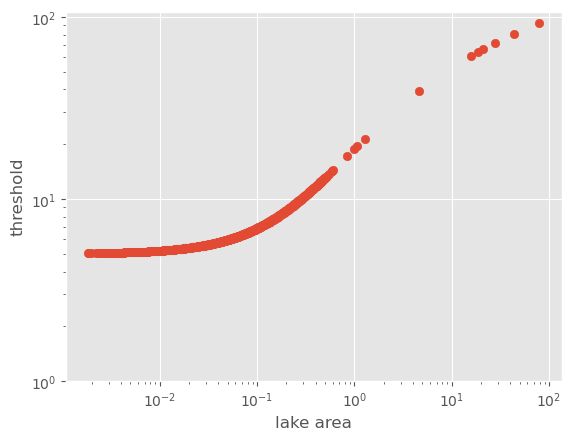

In [7]:
# Derive the distance-to-shore threshold for points to be classed as "outlet" (keep) vs "within-lake" (drop)
threshold = 5 + 20 * np.log(matched_lakes["lakearea_km2"] + 1)

# visualise relationship with lake area
plt.scatter(matched_lakes["lakearea_km2"], threshold, marker='o')
plt.ylabel('threshold')
plt.xlabel('lake area')
plt.xscale('log')
plt.yscale('log')
plt.ylim(ymin=1)
plt.show()

In [8]:
# Next is to also allow monitoring points classified as lakes, if the lake area
# is small compared to the catchment area (i.e. the lake has a short residence time,
# acting like a through-flowing reservoir). What threshold to use?

pts_gdf["lake_area_pt_km2"] = join_pts_lakes["lakearea_km2"].fillna(0)

pts_gdf["lakeA_div_catchA"] = pts_gdf["lake_area_pt_km2"] / pts_gdf["area_km2"]

area_ratio_threshold = 0.05
print(len(pts_gdf.loc[pts_gdf["lakeA_div_catchA"] > area_ratio_threshold]))


# Take a look at ratios of lake area / catch area
pts_gdf["lakeA_div_catchA"].loc[pts_gdf["is_lake_raw"] == True].describe()

901


KeyError: 'is_lake_raw'

In [ ]:
# -----------------------------------------------------------
# Classify monitoring points as lake or river-like
# -----------------------------------------------------------

area_ratio_threshold = 0.005
max_lake_area = 0.5  # km2 (automatically classify large lakes)

# Base condition: point lies within a lake polygon
pts_gdf["is_lake_raw"] = join_pts_lakes.index_right.notna()

# -----------------------------------------------------------
# Define logical components
# -----------------------------------------------------------

in_lake = pts_gdf["is_lake_raw"]
far_from_shore = dist_to_shore > threshold
not_on_shore = dist_to_shore > 2.0 #m

high_ratio = pts_gdf["lakeA_div_catchA"] > area_ratio_threshold
large_lake = pts_gdf["lake_area_pt_km2"] > max_lake_area

few_samples = pts_gdf["n_samples"] <= 2

# -----------------------------------------------------------
# Classification rules for classifying as lake
# -----------------------------------------------------------

# Main hydrological rule
main_rule = in_lake & far_from_shore & (high_ratio | large_lake)

# Override: low-sample sites in lakes (add small distance-to-shore buffer)
low_sample_override = in_lake & few_samples & not_on_shore

# Final classification
pts_gdf["is_lake_buff"] = main_rule | low_sample_override

# -----------------------------------------------------------
# QC / diagnostic breakdown
# -----------------------------------------------------------

base = in_lake & far_from_shore

large_lakes_only = base & large_lake & ~high_ratio
high_ratio_only = base & high_ratio & ~large_lake
overlap = base & high_ratio & large_lake

print("All points within lakes:", in_lake.sum())

print("Points in lakes after distance-to-shore criteria:", base.sum())

print("Classify as lake because of large lakes only:", large_lakes_only.sum())

print("Classify as lake because of high ratio only:", high_ratio_only.sum())

print("Overlap (high ratio AND large lake):", overlap.sum())


# Low-sample diagnostics
low_sample_total = low_sample_override

# Points included ONLY because of override (i.e. would otherwise be excluded)
low_sample_only = low_sample_override & ~main_rule

# Points that satisfy both main rule AND override
low_sample_overlap = low_sample_override & main_rule

print("Low-sample points in lakes (n <= 2):", low_sample_total.sum())

print("...of which added exclusively by override:", low_sample_only.sum())

print("...of which already classified by main rule:", low_sample_overlap.sum())



# -----------------------------------------------------------
# Extract final lake sites
# -----------------------------------------------------------

lake_points_gdf = pts_gdf.loc[pts_gdf["is_lake_buff"]].copy()

print("Number of points in lakes after filtering:", len(lake_points_gdf))


# -----------------------------------------------------------
# Priority sites (based on number of samples)
# -----------------------------------------------------------

lake_points_gdf["priority"] = lake_points_gdf["n_samples"] > n_samps_priority

print(f"Number of (filtered) points in lakes with n > {n_samps_priority} samples:")
print(lake_points_gdf["priority"].value_counts())


# -----------------------------------------------------------
# Summary statistics
# -----------------------------------------------------------

print("Lake points:")
lake_points_gdf.describe()

In [ ]:
# Take a look at points almost flagged as lakes, but "saved" by the area ratio rule
in_lake = pts_gdf["is_lake_raw"]
far_from_shore = dist_to_shore > threshold
high_ratio = pts_gdf["lakeA_div_catchA"] > area_ratio_threshold
large_lake = pts_gdf["lake_area_pt_km2"] > max_lake_area


saved_by_ratio = (
    in_lake &
    far_from_shore &
    (~high_ratio) &      # fails ratio condition
    (~large_lake)        # also not large enough to override
)

saved_points_gdf = pts_gdf.loc[saved_by_ratio].copy()
saved_points_gdf

In [ ]:
# # Plot lake point split into "keep" vs "drop" to optimize/check classification.
# # Result for lakes: pretty happy with classification, almost all point are classified as I would have

# # Plot for all identified points, or just priority points?
# plot_pts_gdf = pts_gdf
# plot_pts_gdf = plot_pts_gdf.loc[plot_pts_gdf['n_samples'] > n_samps_priority]

# # Points inside any lake polygon
# plot_join_pts_lakes = join_pts_lakes.loc[join_pts_lakes['site_code'].isin(plot_pts_gdf['site_code'])]
# in_lake = plot_join_pts_lakes.index_right.notna()

# # Points within threshold (i.e. kept - assume outflows)
# outflow_points = plot_pts_gdf[in_lake & (~plot_pts_gdf["is_lake_buff"])]

# # Points assumed to be lakes
# lake_points = plot_pts_gdf[plot_pts_gdf["is_lake_buff"]]

# lake_ids = plot_join_pts_lakes.loc[in_lake, "index_right"].dropna().unique()

# # Limit to first N lakes
# lake_ids = lake_ids[90:120]

# n = len(lake_ids)
# ncols = 3
# nrows = math.ceil(n / ncols)

# fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 4*nrows))
# axes = axes.flatten()

# for ax, lake_id in zip(axes, lake_ids):

#     # Lake polygon
#     lake = lake_gdf.loc[[lake_id]]

#     # Points linked to this lake
#     mask = plot_join_pts_lakes["index_right"] == lake_id

#     pts_lake = lake_points[mask]
#     pts_outflow = outflow_points[mask]

#     # Plot lake
#     lake.plot(ax=ax, color="lightblue", edgecolor="blue", alpha=0.5)

#     site_id_li = []
#     # Plot interior points (red)
#     if len(pts_lake) > 0:
#         pts_lake.plot(ax=ax, color="red", markersize=20, label="lake")
#         site_id_li.append(pts_lake['site_code'].values[0])

#     # Plot outflow / shoreline points (green)
#     if len(pts_outflow) > 0:
#         pts_outflow.plot(ax=ax, color="green", markersize=20, label="outflow")
#         site_id_li.append(pts_outflow['site_code'].values[0])

#     # Zoom to lake
#     minx, miny, maxx, maxy = lake.total_bounds
#     ax.set_xlim(minx, maxx)
#     ax.set_ylim(miny, maxy)

#     ax.set_title(f"Sites {site_id_li}")
#     ax.set_axis_off()

# plt.tight_layout()
# plt.show()

In [ ]:
# # Manually check priority sites that will be flagged for dropping

# priority_lake_points_gdf = lake_points_gdf.loc[lake_points_gdf['priority'] == True]
# print(len(priority_lake_points_gdf))
# # Associated catchment boundaries
# plot_lake_cat_gdf = cat_gdf.loc[cat_gdf['site_code'].isin(priority_lake_points_gdf['site_code'])]

# # Plots per page
# nrows = 4
# ncols = 3

# fname = f"catchment_thumbnails_{dem_res}-dem_priority-lake-sites_v2.pdf"
# pdf_path = os.path.join(cur_dir, fname)

# create_thumbnail_maps(
#     plot_lake_cat_gdf,
#     priority_lake_points_gdf,
#     pdf_path,
#     nrows,
#     ncols,
#     site_id_col="site_code",
#     area_col="area_km2",
#     n_samples_col="n_samples",
#     add_rivs=True,
#     lake_gdf=lake_gdf,
#     area_threshold=0.5,      # km². For catchs bigger than this, zoom in
#     target_area_km2=0.4  #km2, to zoom to for larger catches
# )

In [ ]:
# Originally I did manual QC to decide which sites to override the is_lake flag. Here are the results.
# However, this is now not needed after adding the lake/catch area criteria

# Come up with list of lakes to exclude, from high-priority sites (all low-priority sites are dropped)

# TODO: derive this based on catch area / lake area
exclude_lake_pts = [
    '016-31838', # Skienselva (widening)
    '019-115349',  # Wide Nisser river, weir
    '021-90018', # Otra (tho not flagged in v2...?)
    '024-58896',  # Small lake on large Lynga system (A=114 km2)
    '050-90050', # river-lake, moving. Catch A 490 km2
    '067-79150', # Tangedalselva (tiny pond on river)
]

print("Original flagged within-lake points:", len(pts_gdf.loc[pts_gdf['is_lake_buff'] == True]))

# Remove within-lake site flags for manual
pts_gdf.loc[pts_gdf["site_code"].isin(exclude_lake_pts), "is_lake_buff"] = False

print("Final flagged within-lake points:", len(pts_gdf.loc[pts_gdf['is_lake_buff'] == True]))

## Identify points located far inside or outside delineated catchments

Because of the minimum area threshold of 0.2 km2 used:
- Points inside the catchment tend to indicate that the catchment had to expand to meet the threshold, i.e. that the site is way too small. This check needs to account for point near the boundary though, so add a buffer. So likely just remove these sites, unless the coordinates were wrong and the point should have been on a nearby mainstem. -> manual check for data-rich sites.
- Points way outside the catchment also tend to indicate that something has gone wrong. E.g. delineation snapped to nearest larger catchment satisfies the minimum area threshold.

In [ ]:
# As points are derived from cat_gdf, we have 1:1 alignment and a shared index,
# so don't need merge, map or lookup. But double-check this
assert (pts_gdf.index == cat_gdf.index).all()

# Distance from each point to its own catchment boundary (metres)
pts_gdf['dist_to_cb'] = pts_gdf.geometry.distance(cat_gdf.geometry.boundary)
print(pts_gdf['dist_to_cb'].describe())

# Classify points as being "well inside" or "well outside"
dist_inside = 40  # metres; allowed distance within/outside catchment polygon

# Inclusion rule
pts_gdf["inside_raw"] = pts_gdf.geometry.within(cat_gdf.geometry)
pts_gdf["inside"] = pts_gdf["inside_raw"] & (pts_gdf["dist_to_cb"] > dist_inside)
pts_gdf["outside_raw"] = ~pts_gdf["inside_raw"]
pts_gdf["outside"] = pts_gdf["outside_raw"] & (pts_gdf["dist_to_cb"] > dist_inside)

# Drop helper cols
pts_gdf = pts_gdf.drop(['inside_raw', 'outside_raw'], axis=1)

print("")
print("Classification of points as inside catchment boundary:")
print(pts_gdf["inside"].value_counts())
print("")
print("Classification of points as outside catchment boundary:")
print(pts_gdf["outside"].value_counts())

print("")

In [ ]:
# pts_gdf.loc[pts_gdf['dist_to_cb'] > 200]

In [ ]:
# # Manually check priority sites

# # Subset to just monitoring points (and associated catchments) with >= 10 samples
# priority_inside_points_gdf = pts_gdf.loc[
#     (pts_gdf['n_samples'] > n_samps_priority) &
#     (pts_gdf["inside"])
# ]

# plot_inside_cat_gdf = cat_gdf.loc[cat_gdf['site_code'].isin(priority_inside_points_gdf['site_code'])]

# print("Data-rich sites classified as 'inside' for manual checking:", len(priority_inside_points_gdf))

# # ---------- PLOT -----------
# # Plots per page
# nrows = 4
# ncols = 3

# fname = f"catchment_thumbnails_{dem_res}-dem_priority-inside-catch-sites.pdf"
# pdf_path = os.path.join(cur_dir, fname)

# create_thumbnail_maps(
#     plot_inside_cat_gdf,
#     priority_inside_points_gdf,
#     pdf_path,
#     nrows,
#     ncols,
#     site_id_col="site_code",
#     area_col="area_km2",
#     n_samples_col="n_samples",
#     add_rivs=True,
#     lake_gdf=lake_gdf
# )

In [ ]:
# # Manually check priority sites - OUTSIDE

# # Subset to just monitoring points (and associated catchments) with >= 10 samples
# priority_outside_points_gdf = pts_gdf.loc[
#     (pts_gdf['n_samples'] > n_samps_priority) &
#     (pts_gdf["outside"])
# ]

# plot_outside_cat_gdf = cat_gdf.loc[cat_gdf['site_code'].isin(priority_outside_points_gdf['site_code'])]

# print("Data-rich sites classified as 'outside' for manual checking:", len(priority_outside_points_gdf))

# # ---------- PLOT -----------
# # Plots per page
# nrows = 4
# ncols = 3

# fname = f"catchment_thumbnails_{dem_res}-dem_priority-outside-catch-sites.pdf"
# pdf_path = os.path.join(cur_dir, fname)

# create_thumbnail_maps(
#     plot_outside_cat_gdf,
#     priority_outside_points_gdf,
#     pdf_path,
#     nrows,
#     ncols,
#     site_id_col="site_code",
#     area_col="area_km2",
#     n_samples_col="n_samples",
#     add_rivs=True,
#     lake_gdf=lake_gdf
# )

In [ ]:
# After manual checking:

# Remove "inside" flag for following catchments: manual check showed that they were identified because
# the elvis line is far from the river bank (i.e. mostly big rivers)
inside_exceptions = [
    '002-38516',
    '012-80736',
    '013-98371',
    '015-81468',
    '022-79224',
    '026-82802',
    '036-58748',
    '238-96381'
]

print("Original flagged 'inside catchment' points:", len(pts_gdf.loc[pts_gdf['inside'] == True]))

# Remove inside flags for some sites
pts_gdf.loc[pts_gdf["site_code"].isin(inside_exceptions), "inside"] = False

print("Final flagged 'inside catchment' points:", len(pts_gdf.loc[pts_gdf['inside'] == True]))

In [157]:
# After manual checking of "outside" points:

# No need to redelineate for these, they are bank samples but on the right river
outside_exceptions = [
    '002-63531',
    '015-90017',
    '016-112600',
    '021-122044',
    '084-120170',
    '234-38533',
]

print("Original flagged 'outside catchment' points:", len(pts_gdf.loc[pts_gdf['outside'] == True]))

# Remove inside flags for some sites
pts_gdf.loc[pts_gdf["site_code"].isin(outside_exceptions), "outside"] = False

print("Final flagged 'outside catchment' points:", len(pts_gdf.loc[pts_gdf['outside'] == True]))

# For all remaining (data-rich only?) catchments with the monitoring point outside the catchment: re-do delineation

Original flagged 'outside catchment' points: 341
Final flagged 'outside catchment' points: 335


In [158]:
# Make a list of sites to drop altogether for other random reasons, spotted during above QC (i.e.
# all within the points flagged as being potential lake, inside or outside points)
other_drop_site_li = [
    '012-122527', #	Reservoir outflow? Natural outflow further north though, so miles from outflow line
    '246-103043', # Steintipp
    '246-103018', # Steintipp
    '246-103035', # Steintipp
    '246-103042', # Steintipp
    '002-64072',  # tiny, n=12, no visible waterway, point outside catch
    '002-64070', # tiny, n=12, no visible waterway, point outside catch
    '002-64073', # tiny, n=12, no visible waterway, point outside catch
    '002-64074', # tiny, n=9, no visible waterway
    '002-64075', # tiny, n=9, no visible waterway
    '003-122101', # tiny, Rygge airport, no visible waterway, point outside catch
    '101-65170', # tiny, no visible waterway, point outside catch
    '109-81177', # tiny, no visible waterway, point outside catch
    '186-118096', # tiny, no visible waterway, point outside catch, n=40, runoff from airport
]

pts_gdf['drop_other'] = False
pts_gdf.loc[pts_gdf['site_code'].isin(other_drop_site_li), 'drop_other'] = True
print((pts_gdf['drop_other']==True).sum())

14


In [159]:
# Recheck inside and outside sites
print("Final flagged 'inside catchment' points:", len(pts_gdf.loc[pts_gdf['inside'] == True]))
print("Final flagged 'outside catchment' points:", len(pts_gdf.loc[pts_gdf['outside'] == True]))

Final flagged 'inside catchment' points: 377
Final flagged 'outside catchment' points: 335


In [160]:
pts_gdf.loc[pts_gdf['site_code'] == '001-39477']

,site_code,lon,lat,site_id,Name,start_year,end_year,n_years,n_samples,av_freq,area_km2,geometry,is_lake_raw,is_lake_buff,lake_area_pt_km2,lakeA_div_catchA,dist_to_cb,inside,outside,drop_other
49,001-39477,11.574794,59.826674,39477,Svarttjenn utløp,2005,2024,19.0,18,0.95,0.265572,POINT (308008.091 6637071.983),True,True,0.015562,0.058598,8.016823,False,False,False


## After excluding the above flagged sites, check coords & min threshold of remaining data-rich sites

Workflow involved:
* Dropping sites so far identified as being within-lake or "dodgy" for some other reason. Leaves 10 329 sites (original was 10 857, i.e. dropped 528)
* Filtering to only include sites with n > n_samps_priority (9).
  
* **Small sites:**
  Filter to sites with catchment area <= 5 km2 (around half of sites, i.e. 5144), and to only data-rich sites (956 sites). Plot thumbnails for all 956 sites and manually check. Looking especially for:
     * In-lake points not flagged so far (i.e. close to the shore but not an outflow): 5
     * Monitoring points close to the main channel but delineated as a small tributary catchment instead: check shouldn't be the mainstem. If it should, increase the minimum area threshold for catchment delineation to an appropraite value. Decide what this value should be using the regine the monitoring point is in and NVE Atlas (which includes "upstream area" attribute for many reginer). If not available, estimate using Vannmiljø polygon measuring tool.
     * Whether the correct catchment is being delineated for monitoring points located close to forks.
     * **Result:** 67 (7%) of monitoring points either needing new coordinates (9), and/or a different minimmum are threshold (52), or flagged as being to drop (lakes or other "dodgy" site) (14)
     * i.e. can probably assume about a **7% error** in the more data-poor small catchments that weren't checked manually.

* **Large sites:**
   Filter to sites with a catchment area > 5 km2 (around half the sites), and to only data-rich sites (1767). Plot thumbnails for all, zooming in for most catchments. Manually check, looking especially for:
     * In-lake monitoring points (as with small catches): 1
     * Forks (as with small catches). Where the wrong land area was being included, correcting it usually involved having to move the monitoring point coordinates a small distance (<= 50 m) up- or down-stream of the real location. Occasionally also altering the minimum area threshold.
     * Monitoring points located off the mainstem. Find that usually any offset is because of inaccuracies in the elvis river network, or because the river is so wide that the single mid-line of the elvis network is a long way from near-bank sampling locations. However, in some cases a small side tribuary is incorrectly classed as the mainstam. Note: often this is very subtle, so there is definitely a risk of not having captured all issues here.
     * **Result:** 29 monitoring points either needing new coordinates (16), a different minimmum are threshold (4), or flagged as being to drop (lakes or other "dodgy" site) (9)
     * i.e. can probably assume a 1-2% error in the more data-poor large catchment delineations that weren't checked manually.

For both, when this manual inspection revealed that the site should be excluded for some reason, add a flag to drop it. Reasons documented, and included things like: hydropower tunnel outlet from distant catchment, urban culvert outlet (unknown source area), tiny sampling point with no obvious stream network nearby (either elvis or on the more detailed basemap), small ditches from e.g. factories or airports, small pits/ravines without an obvious catchment, etc. Total identified for dropping: 17 sites (9 from small, 8 from big).

Overall, the large sites had way fewer errors/dodgy/lake sites than the small sites (7% vs 1.6% error rate). So for the data-poor sites, we can trust the larger catchments more.

Manual checking results, with new coordinates, new minimum area thresholds, and flags for sites to drop (due to general "dodgy" or being "lake" sites) are all kept track of in an excel file, ready for a new round of catchment delineation.

### Update pts_gdf, dropping sites so far identified as lakes or other "dodgy"

In [161]:
filt_pts_gdf = pts_gdf.loc[
    (pts_gdf['is_lake_buff'] == False) &
    (pts_gdf['drop_other'] == False)
]

filt_pts_gdf = filt_pts_gdf.drop(['is_lake_buff', 'drop_other'], axis=1)

filt_cat_gdf = cat_gdf.loc[cat_gdf['site_code'].isin(filt_pts_gdf['site_code'])]

print("Sites before removing lakes & other 'dodgy' sites:", len(pts_gdf))
print("Sites after removal:", len(filt_pts_gdf))

# Recheck inside and outside sites - probably quite a few of these were lakes
print("Final flagged 'inside catchment' points:", len(filt_pts_gdf.loc[filt_pts_gdf['inside'] == True]))
print("Final flagged 'outside catchment' points:", len(filt_pts_gdf.loc[filt_pts_gdf['outside'] == True]))

Sites before removing lakes & other 'dodgy' sites: 10857
Sites after removal: 9372
Final flagged 'inside catchment' points: 191
Final flagged 'outside catchment' points: 216


### Make output for manual QC

In [162]:
area_thresh = 5  # km2

filt_pts_gdf['small'] = (filt_pts_gdf['area_km2'] < area_thresh)
filt_pts_gdf["small"].value_counts()

small
False    5101
True     4271
Name: count, dtype: int64

In [163]:
# Manually check data-rich sites that I haven't already checked as part of 'inside' or 'outside' datasets -> SMALL CATCHS

plot_pts_gdf = filt_pts_gdf.loc[
    (filt_pts_gdf['small'] == True) &
    (filt_pts_gdf['n_samples'] > n_samps_priority) &
    (filt_pts_gdf['inside'] == False) &
    (filt_pts_gdf['outside'] == False)
]

plot_cat_gdf = cat_gdf.loc[cat_gdf['site_code'].isin(plot_pts_gdf['site_code'])]

print("Small data-rich sites for manual checking:", len(plot_pts_gdf))

# # ---------- PLOT -----------
# # Plots per page
# nrows = 4
# ncols = 3

# fname = f"catchment_thumbnails_{dem_res}-dem_priority-small-catch-sites.pdf"
# pdf_path = os.path.join(cur_dir, fname)

# create_thumbnail_maps(
#     plot_cat_gdf,
#     plot_pts_gdf,
#     pdf_path,
#     nrows,
#     ncols,
#     site_id_col="site_code",
#     area_col="area_km2",
#     n_samples_col="n_samples",
#     add_rivs=True,
#     lake_gdf=lake_gdf
# )

Small data-rich sites for manual checking: 912


In [164]:
# Manually check data-rich sites that I haven't already checked as part of 'inside' or 'outside' datasets -> LARGE CATCHS

plot_pts_gdf = filt_pts_gdf.loc[
    (filt_pts_gdf['small'] == False) &
    (filt_pts_gdf['n_samples'] > n_samps_priority) &
    (filt_pts_gdf['inside'] == False) &
    (filt_pts_gdf['outside'] == False)
]

plot_cat_gdf = cat_gdf.loc[cat_gdf['site_code'].isin(plot_pts_gdf['site_code'])]

print("Data-rich sites for manual checking (large catchs):", len(plot_pts_gdf))

# # ---------- PLOT -----------
# # Plots per page
# nrows = 4
# ncols = 3

# fname = f"catchment_thumbnails_{dem_res}-dem_priority-large-catch-sites.pdf"
# pdf_path = os.path.join(cur_dir, fname)

# create_thumbnail_maps(
#     plot_cat_gdf,
#     plot_pts_gdf,
#     pdf_path,
#     nrows,
#     ncols,
#     site_id_col="site_code",
#     area_col="area_km2",
#     n_samples_col="n_samples",
#     add_rivs=True,
#     lake_gdf=lake_gdf
# )

Data-rich sites for manual checking (large catchs): 1758


# Make dataframe of points for re-delineation

Redo:
* All points which are classified as "inside" or "outside" the delineated catchment boundary. Use min_threshold=0.05
* All points with area < 0.23 (very close to threshold...), with min_threshold = 0.05
* All points in excel file with results of manual checking of data-rich sites

In [183]:
# Read in results of manual QC of data-rich sites
qc_fpath = r"/home/jovyan/shared/common/norsink/spatial/monitored_chem_catchments/catch_delineation_v1_manual_qc.xlsx"
qc_df = pd.read_excel(qc_fpath)

# Check for duplicate sites
dupes = qc_df["site_code"][qc_df["site_code"].duplicated()]

if len(dupes) >= 1:
    print(f"{dupes.nunique()} duplicated site_codes found:")
    print(sorted(dupes.unique()))
else:
    print("No duplicates")

qc_df.head()

No duplicates


,site_code,new_lon,new_lat,min_area_km2,check_raw_coords,drop,lake,comment,Regine_us_area,Area,N
0,021-122054,NaN,NaN,NaN,NaN,1.0,NaN,Hydro tunnel outflow,NaN,NaN,NaN
1,139-110429,NaN,NaN,NaN,NaN,1.0,NaN,Funny backwater on mainstem of larger river,NaN,NaN,NaN
2,197-92581,NaN,NaN,NaN,NaN,1.0,NaN,Bog in Tromsø airport,NaN,NaN,NaN
3,246-103034,NaN,NaN,NaN,NaN,1.0,NaN,Steintipp,NaN,NaN,NaN
4,246-103036,NaN,NaN,NaN,NaN,1.0,NaN,Steintipp,NaN,NaN,NaN


In [184]:
# Add flags to drop lakes and other sites that should be excluded for some reason (detailed in "Comment" col)

pts_v2_intermediate_gdf = filt_pts_gdf.copy()

# (N.B. definition of a lake changed since doing the manual QC, all but 1 of them now already dropped)

pts_v2_intermediate_gdf["drop_other"] = pts_v2_intermediate_gdf["site_code"].isin(
    qc_df.loc[qc_df["drop"] == 1, "site_code"]
)

pts_v2_intermediate_gdf["is_lake"] = pts_v2_intermediate_gdf["site_code"].isin(
    qc_df.loc[qc_df["lake"] == 1, "site_code"]
)

print("final other points to drop:", len(pts_v2_intermediate_gdf.loc[pts_v2_intermediate_gdf['drop_other'] == True]))
print("final lakes to drop:", len(pts_v2_intermediate_gdf.loc[pts_v2_intermediate_gdf['is_lake'] == True]))

final other points to drop: 35
final lakes to drop: 1


In [185]:
# Update lat/lon and associated point geometry

# Build lookup series
lat_map = qc_df.set_index("site_code")["new_lat"].dropna()
lon_map = qc_df.set_index("site_code")["new_lon"].dropna()

# Map values
new_lat = pts_v2_intermediate_gdf["site_code"].map(lat_map)
new_lon = pts_v2_intermediate_gdf["site_code"].map(lon_map)

# Mask where QC provides coords
mask_available = new_lat.notna() & new_lon.notna()

# Mask where coords actually change
mask_changed = (
    mask_available &
    (
        (pts_v2_intermediate_gdf["lat"] != new_lat) |
        (pts_v2_intermediate_gdf["lon"] != new_lon)
    )
)

# --- Tracking ---
n_available = mask_available.sum()
n_changed = mask_changed.sum()
n_unchanged = n_available - n_changed

print(f"QC coordinates available for {n_available} sites")
print(f"Coordinates updated for {n_changed} sites")
print(f"QC coords matched existing values for {n_unchanged} sites")

# --- Apply updates ---
pts_v2_intermediate_gdf.loc[mask_available, "lat"] = new_lat[mask_available]
pts_v2_intermediate_gdf.loc[mask_available, "lon"] = new_lon[mask_available]

# Update geometry only where changed

updated_points = gpd.GeoDataFrame(
    pts_v2_intermediate_gdf.loc[mask_changed].copy(),
    geometry=gpd.points_from_xy(
        pts_v2_intermediate_gdf.loc[mask_changed, "lon"],
        pts_v2_intermediate_gdf.loc[mask_changed, "lat"]
    ),
    crs="EPSG:4326"
).to_crs(pts_v2_intermediate_gdf.crs)

pts_v2_intermediate_gdf.loc[mask_changed, "geometry"] = updated_points.geometry.values


# Verify geometry is valid
if not pts_v2_intermediate_gdf.geometry.is_valid.all():
    print("WARNING: Some geometries are invalid")

# ---------  QC -----------------
# All site_codes in qc_df that *should* have coords
qc_sites_with_coords = qc_df.loc[
    qc_df["new_lat"].notna() & qc_df["new_lon"].notna(),
    "site_code"
]

# Which of those exist in pts_v2_intermediate_gdf?
gdf_sites = set(pts_v2_intermediate_gdf["site_code"])

missing_in_gdf = set(qc_sites_with_coords) - gdf_sites

# --- Print warnings ---
if missing_in_gdf:
    print(f"WARNING: {len(missing_in_gdf)} site(s) with updated coordinates in qc_df not found in pts_v2_intermediate_gdf:")
    print(sorted(missing_in_gdf))

QC coordinates available for 26 sites
Coordinates updated for 26 sites
QC coords matched existing values for 0 sites
['001-39316', '001-40820', '001-41500', '001-48064', '001-48335']


In [186]:
# Specify minimum area threshold to use in catchment delineation
default_a = 0.2

# Start with default
pts_v2_intermediate_gdf["min_area_km2"] = default_a

# ---- Rule group: set to 0.05 -------
mask_small_or_flagged = (
    (pts_v2_intermediate_gdf["area_km2"] < 0.23) |
    (pts_v2_intermediate_gdf["inside"]) |
    (pts_v2_intermediate_gdf["outside"])
)

pts_v2_intermediate_gdf.loc[mask_small_or_flagged, "min_area_km2"] = 0.05

# --- QC override (highest priority) ---
qc_min_area_map = qc_df.set_index("site_code")["min_area_km2"].dropna()

qc_values = pts_v2_intermediate_gdf["site_code"].map(qc_min_area_map)

mask_qc_override = qc_values.notna()

pts_v2_intermediate_gdf.loc[mask_qc_override, "min_area_km2"] = qc_values[mask_qc_override]

# ----------- Tracking ----------------
n_default = (pts_v2_intermediate_gdf["min_area_km2"] == default_a).sum()
n_small_flagged = mask_small_or_flagged.sum()
n_qc = mask_qc_override.sum()

print(f"Set by default ({default_a}): {n_default}")
print(f"Set to 0.05 (at threshold, or flagged by auto-QC): {n_small_flagged}")
print(f"Min area threshold reset by manual-QC: {n_qc}")

pts_v2_intermediate_gdf.head()

Set by default (0.2): 8768
Set to 0.05 (at threshold, or flagged by auto-QC): 545
Min area threshold reset by manual-QC: 77


,site_code,lon,lat,site_id,Name,start_year,end_year,n_years,n_samples,av_freq,...,lake_area_pt_km2,lakeA_div_catchA,dist_to_cb,inside,outside,small,f_outside_no,drop_other,is_lake,min_area_km2
0,001-119928,11.653745,59.476520,119928,Oppstrøms Bommen RA,2011,2025,14.0,14,1.00,...,0.0,0.0,4.570377,False,False,False,0.009989,False,False,0.2
1,001-119929,11.654461,59.472300,119929,Nedstrøms Bommen RA,2011,2025,14.0,14,1.00,...,0.0,0.0,22.198387,False,False,False,0.009983,False,False,0.2
2,001-30653,11.437438,59.070299,30653,YSTE YSTEHEDEBEKKEN,1987,1987,1.0,4,4.00,...,0.0,0.0,8.430665,False,False,False,-0.000205,False,False,0.2
3,001-30683,11.295421,59.121185,30683,"Unnebergbekken, UNNE",1987,2016,29.1,5,0.17,...,0.0,0.0,1.650297,False,False,False,-0.000290,False,False,0.2
4,001-30687,11.528412,58.987892,30687,ØRB2 ØRBEKKEN,1991,1991,1.0,4,4.00,...,0.0,0.0,5.229977,False,False,False,-0.000143,False,False,0.2


In [187]:
# Add flag to say whether to redelineate or not

# Get full list of site codes to update
update_site_li = set(qc_sites_with_coords).union(  # sites with new coordinates
    pts_v2_intermediate_gdf.loc[mask_small_or_flagged, "site_code"],  # small or flagged as inside or outside
    pts_v2_intermediate_gdf.loc[mask_qc_override, "site_code"]  # sites with new min area threshold
)

# Make boolean column
pts_v2_intermediate_gdf['delineate_v2'] = pts_v2_intermediate_gdf['site_code'].isin(update_site_li)

len(update_site_li)

612

Is this right?

In [188]:
print(len(qc_sites_with_coords))
print(len(pts_v2_intermediate_gdf.loc[mask_small_or_flagged, "site_code"]))  # small or flagged as inside or outside
print(len(pts_v2_intermediate_gdf.loc[mask_qc_override, "site_code"]))  # sites with new min area threshold

print(31+545+77)

31
545
77
653


The individual lists add up to 653 sites, while update_site_li is 612. So we expect **41 sites** to be overapping across lists. Double-check this.

In [189]:
# If the separate lists have 846 sites, and the union has 811, double-check the union...

s1 = set(qc_sites_with_coords)  # new coords
s2 = set(pts_v2_intermediate_gdf.loc[mask_small_or_flagged, "site_code"])  # small, inside, outside
s3 = set(pts_v2_intermediate_gdf.loc[mask_qc_override, "site_code"])  # new min threshold

overlap_12 = s1 & s2  # new coords AND small, inside or outside
overlap_13 = s1 & s3  # new coords AND new min threshold
overlap_23 = s2 & s3  # small, inside, outside AND new min threshold

overlap_all = s1 & s2 & s3

print("new coords AND small, inside or outside:", len(overlap_12))
print("new coords AND new min threshold:", len(overlap_13))
print("(small, inside, outside) AND new manually-specified min threshold:", len(overlap_23))
print("all three:", len(overlap_all))

duplicate_sites = (
    (s1 & s2)
    | (s1 & s3)
    | (s2 & s3)
)

print("Overlapping sites:", len(duplicate_sites))  # should be 35

new coords AND small, inside or outside: 0
new coords AND new min threshold: 24
(small, inside, outside) AND new manually-specified min threshold: 17
all three: 0
Overlapping sites: 41


In [190]:
# Tidy pts_v2_gdf

# Drop sites which won't be carried forward
pts_v2_gdf = pts_v2_intermediate_gdf.loc[
    (pts_v2_intermediate_gdf['is_lake'] == False) &
    (pts_v2_intermediate_gdf['drop_other'] == False)
].copy()

print("Sites before removing additional manually identified lakes & other 'dodgy' sites:", len(pts_v2_intermediate_gdf))
print("Sites after removal:", len(pts_v2_gdf))

# Rename columns that will become wrong with redelineation
cols_to_rename = ['area_km2', 'dist_to_cb', 'inside', 'outside', 'f_outside_no', 'is_lake_raw']
pts_v2_gdf = pts_v2_gdf.rename(columns={col: f"{col}_v1" for col in cols_to_rename})

# Drop unnecessary columns
pts_v2_gdf = pts_v2_gdf.drop(['is_lake', 'drop_other', 'small', 'lake_area_pt_km2', 'lakeA_div_catchA'], axis=1)

pts_v2_gdf.head()

Sites before removing additional manually identified lakes & other 'dodgy' sites: 9372
Sites after removal: 9336


,site_code,lon,lat,site_id,Name,start_year,end_year,n_years,n_samples,av_freq,area_km2_v1,geometry,is_lake_raw_v1,dist_to_cb_v1,inside_v1,outside_v1,f_outside_no_v1,min_area_km2,delineate_v2
0,001-119928,11.653745,59.476520,119928,Oppstrøms Bommen RA,2011,2025,14.0,14,1.00,1008.505005,POINT (310465.118 6597884.57),False,4.570377,False,False,0.009989,0.2,False
1,001-119929,11.654461,59.472300,119929,Nedstrøms Bommen RA,2011,2025,14.0,14,1.00,1009.065359,POINT (310481.985 6597412.97),False,22.198387,False,False,0.009983,0.2,False
2,001-30653,11.437438,59.070299,30653,YSTE YSTEHEDEBEKKEN,1987,1987,1.0,4,4.00,6.702626,POINT (295802 6553328.19),False,8.430665,False,False,-0.000205,0.2,False
3,001-30683,11.295421,59.121185,30683,"Unnebergbekken, UNNE",1987,2016,29.1,5,0.17,15.372746,POINT (287981.65 6559432.015),False,1.650297,False,False,-0.000290,0.2,False
4,001-30687,11.528412,58.987892,30687,ØRB2 ØRBEKKEN,1991,1991,1.0,4,4.00,42.291160,POINT (300536.51 6543885.23),False,5.229977,False,False,-0.000143,0.2,False


In [191]:
# Make pt_df of points to redo delineation for
pts_redelineate_v2_gdf = pts_v2_gdf.loc[pts_v2_gdf['delineate_v2'] == True].copy()

pts_redelineate_v2_gdf = pts_redelineate_v2_gdf.drop(['delineate_v2'], axis=1)

pts_redelineate_v2_gdf

,site_code,lon,lat,site_id,Name,start_year,end_year,n_years,n_samples,av_freq,area_km2_v1,geometry,is_lake_raw_v1,dist_to_cb_v1,inside_v1,outside_v1,f_outside_no_v1,min_area_km2
36,001-38856,11.359621,59.853254,38856,"Viketjenn, utløp",2005,2024,19.0,19,1.00,1.820401,POINT (296117.534 6640672.357),True,70.348994,True,False,-0.000219,0.05
95,001-48250,11.535310,59.029610,48250,"Ellefsrødtjernet, utløp",2011,2022,10.9,4,0.37,1.561725,POINT (301173.499 6548506.022),True,4.413102,False,False,-0.000176,0.20
112,001-48333,11.489173,58.890788,48333,Svendstjern,2011,2011,1.0,1,1.00,0.227953,POINT (297715.542 6533200.06),False,20.549095,False,False,-0.000205,0.05
117,001-48357,11.593958,59.013004,48357,"Åletjern, utløp",2020,2020,1.0,1,1.00,0.201972,POINT (304442.969 6546485.312),False,30.508576,False,False,-0.000137,0.05
140,001-48472,11.596141,59.253100,48472,"Ormtjern Midtre, utløp",2011,2022,11.1,4,0.36,0.200375,POINT (305932 6573192),False,48.000002,True,False,-0.000124,0.05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10574,224-58666,25.024120,70.089780,58666,Bekk ved Norgård,2011,2011,1.0,2,2.00,1.022011,POINT (879491.304 7807196.11),False,53.909742,False,True,0.386170,0.05
10646,234-M3,25.144760,69.395210,-3,Karasjohka,2022,2022,1.0,159,159.00,0.623298,POINT (896868.148 7731425.499),False,25.498875,False,False,-0.003051,1000.00
10651,236-81604,29.238586,70.836943,81604,"Styrdalselva , Q3 sidesig",2016,2016,1.0,3,3.00,4.652986,POINT (1017424.954 7920323.597),False,109.364364,False,True,-0.005720,0.05
10670,246-103015,29.938335,69.640030,103015,"Langfjordtunnellen, utløp",2019,2025,6.1,5,3.00,0.366517,POINT (1075035.1 7796508.1),False,186.176242,False,True,-0.007320,0.05


## Save

In [194]:
cur_dir = r"/home/jovyan/shared/common/norsink/spatial/monitored_chem_catchments"
dem_res = 20  # m

# All monitoring points after cleaning and filtering
full_pt_fpath = os.path.join(cur_dir, "outlet_locations_vm-rivs-quant-oc_v2-full.csv")
pts_v2_gdf.to_csv(full_pt_fpath, index=False)

# Monitoring points for v2 of catchment delineation
redelineate_pt_fpath = os.path.join(cur_dir, "outlet_locations_vm-rivs-quant-oc_v2-for-redelineation.csv")
pts_redelineate_v2_gdf.to_csv(redelineate_pt_fpath, index=False)

In [192]:
# QC plot of v2 of sites (all) - all plot in Norway, good
plot_stn_gdf = pts_v2_gdf.rename({'lon': 'longitude', 'lat': 'latitude'}, axis=1).reset_index()

print(len(plot_stn_gdf), "River stations in Norway with OC data")
nivapy.spatial.quickmap(
    plot_stn_gdf, kartverket=True, popup='site_code', aerial_imagery=False
)

9336 River stations in Norway with OC data


In [193]:
# QC plot of v2 of sites for redelineation, dropping ones with big area threshold already specified

plot_stn_gdf = pts_redelineate_v2_gdf.rename({'lon': 'longitude', 'lat': 'latitude'}, axis=1).reset_index()
plot_stn_gdf = plot_stn_gdf.loc[plot_stn_gdf['min_area_km2'] <= 0.2]

print(len(plot_stn_gdf), "River stations in for redelineation")
nivapy.spatial.quickmap(
    plot_stn_gdf, kartverket=True, popup='site_code', aerial_imagery=False
)

523 River stations in for redelineation


In [102]:
pts_redelineate_v2_gdf.loc[pts_redelineate_v2_gdf['site_code'] == '024-94936']

,site_code,lon,lat,site_id,Name,start_year,end_year,n_years,n_samples,av_freq,area_km2_v1,geometry,dist_to_cb_v1,inside_v1,outside_v1,f_outside_no_v1,min_area_km2
6417,024-94936,7.114131,58.195023,94936,Bekk frå Udlandsvatn,2018,2019,1.0,4,4.0,475.84946,POINT (37063.108 6477564.183),44.183077,True,False,-0.004284,0.05
